# Main-text figures and tables for the Results chapter


In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Markdown

repo = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "reported_runs/analysis").is_dir())
sys.path.insert(0, str(repo)) if str(repo) not in sys.path else None
from reported_runs.analysis.presentation import load_results, NotebookReport, label_conditions, rank_summary
from reported_runs.analysis import main_text as mt
%matplotlib inline

results = load_results()
report = NotebookReport(results, 'main')
trajectory = label_conditions(results["trajectory"])
sources = results["sources"]
effect_summaries = results["effect_summaries"]
mt.use_print_style()
main_figures = []
pd.set_option("display.max_columns", 18)
pd.set_option("display.max_rows", 60)

## RQ I: feedback mechanisms


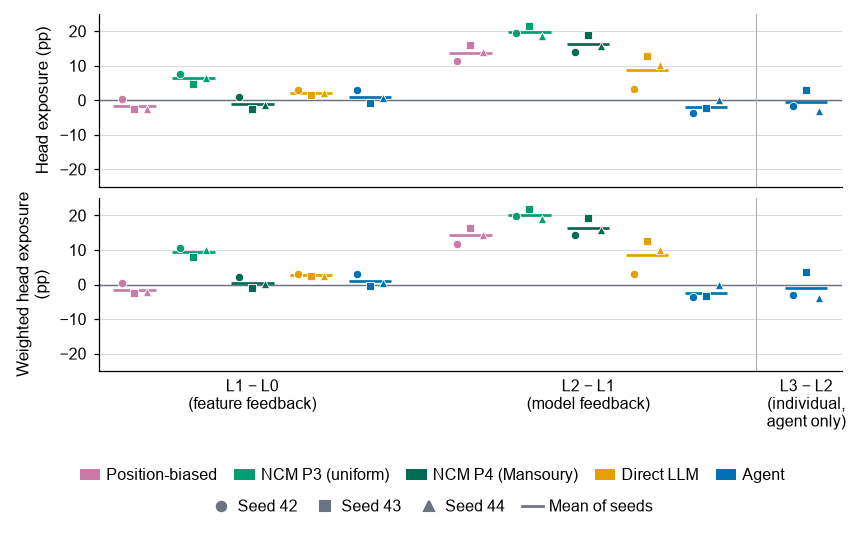

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq1_feedback_exposure.pdf) · label `chap:results:fig:main_rq1_feedback_exposure`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,L1 minus L0 (feature feedback),Position-biased,Head exposure,0.295556,-2.56889,-2.46111,-1.57815,3
1,L1 minus L0 (feature feedback),Position-biased,Weighted head exposure,0.31597,-2.583,-2.21398,-1.49367,3
2,L1 minus L0 (feature feedback),NCM P3 (uniform),Head exposure,7.72556,4.85111,6.58,6.38556,3
3,L1 minus L0 (feature feedback),NCM P3 (uniform),Weighted head exposure,10.4575,7.94124,9.89841,9.43238,3
4,L1 minus L0 (feature feedback),NCM P4 (Mansoury),Head exposure,0.862222,-2.40111,-1.25667,-0.931852,3
5,L1 minus L0 (feature feedback),NCM P4 (Mansoury),Weighted head exposure,2.13767,-1.10345,0.068401,0.367542,3
6,L1 minus L0 (feature feedback),Direct LLM,Head exposure,2.90333,1.56778,2.06111,2.17741,3
7,L1 minus L0 (feature feedback),Direct LLM,Weighted head exposure,3.0976,2.43386,2.61001,2.71382,3
8,L1 minus L0 (feature feedback),Agent,Head exposure,3.08556,-0.694444,0.656667,1.01593,3
9,L1 minus L0 (feature feedback),Agent,Weighted head exposure,2.97379,-0.524093,0.50293,0.984209,3


LaTeX label: `chap:results:tab:main_rq1_feedback_exposure_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq1_feedback_exposure_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq1_feedback_exposure_values.csv)

In [2]:
feedback_effects = effect_summaries.loc[effect_summaries.study.eq('movielens_feedback_a300_e804') & effect_summaries.kind.isin(['feedback', 'individual'])]
F1_LABELS = {'L1 minus L0': 'L1 − L0\n(feature feedback)', 'L2 minus L1': 'L2 − L1\n(model feedback)',
             'L3 full reflection minus L2 frozen agent': 'L3 − L2\n(individual,\nagent only)'}
figure = mt.effect_panels(feedback_effects, ['head_exposure', 'weighted_head_exposure'], categories=list(F1_LABELS),
                          category_labels=F1_LABELS, separators=['L3 full reflection minus L2 frozen agent'], limits=(-25, 25))
main_figures.append(mt.export_main_figure(report, figure, 'main_rq1_feedback_exposure', ""))
report.table(mt.effect_values(figure.plotted, category_labels=F1_LABELS), 'main_rq1_feedback_exposure_values',
             "")

In [3]:
from reported_runs.analysis.advertising_slots import load_advertising_slot_metrics
from reported_runs.analysis.advertising_views import build_slot_views
sampling_effects = effect_summaries.loc[effect_summaries.kind.eq('sampling')]
slot_sources = sources.loc[sources.study.eq('movielens_sampling_outcome_a150_r150_e804') & sources.condition_id.str.startswith('O')]
slot_metrics = load_advertising_slot_metrics(slot_sources, repo, repo / 'reported_runs/analysis/cache/advertising_slots')
slot_effects = build_slot_views(slot_metrics, results['comparison_plan'])['effect_summaries']
l4_l5 = mt.l4_l5_effect_table(sampling_effects, slot_effects)
report.table(l4_l5, 'main_rq1_l4_l5_effects',
             "", source_frame=pd.concat([sampling_effects, slot_effects]))

,Contrast,Exposure scope,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,"L4 departures, no refill minus L3",Ranks 1–10,Head exposure,1.38179,2.08382,0.124623,1.19674,3
1,"L4 departures, no refill minus L3",Ranks 1–10,Weighted head exposure,1.19931,2.29153,0.375844,1.2889,3
2,L4 uniform refill minus L3,Ranks 1–10,Head exposure,-1.74889,-1.54889,-1.02444,-1.44074,3
3,L4 uniform refill minus L3,Ranks 1–10,Weighted head exposure,-2.06809,-1.77437,-1.03369,-1.62538,3
4,L4 cluster refill minus L3,Ranks 1–10,Head exposure,-0.295556,0.577778,1.06444,0.448889,3
5,L4 cluster refill minus L3,Ranks 1–10,Weighted head exposure,-0.779832,0.250431,0.923529,0.131376,3
6,Static advertising minus organic control,Ranks 2–10,Head exposure,0.682623,-2.06742,-5.68148,-2.35543,3
7,Static advertising minus organic control,Ranks 2–10,Weighted head exposure,0.943134,-2.39542,-6.90936,-2.78722,3
8,L5 adaptive minus static advertising,Ranks 2–10,Head exposure,-2.70564,-1.56715,1.47901,-0.931257,3
9,L5 adaptive minus static advertising,Ranks 2–10,Weighted head exposure,-2.77956,-1.48133,2.47869,-0.594066,3


LaTeX label: `chap:results:tab:main_rq1_l4_l5_effects` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq1_l4_l5_effects.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq1_l4_l5_effects.csv)

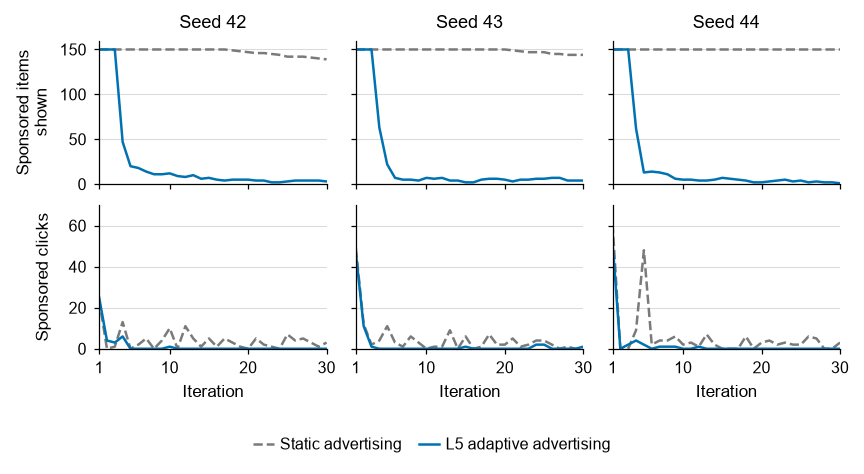

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq1_advertising_delivery.pdf) · label `chap:results:fig:main_rq1_advertising_delivery`

In [4]:
from reported_runs.analysis.sections_rq1_3 import advertising_display
advertising = advertising_display(label_conditions(results['advertising'].loc[
    results['advertising'].study.eq('movielens_sampling_outcome_a150_r150_e804') & results['advertising'].condition_id.str.startswith('O')]))
figure = mt.advertising_delivery(advertising)
main_figures.append(mt.export_main_figure(report, figure, 'main_rq1_advertising_delivery', ""))

## RQ II: user response models


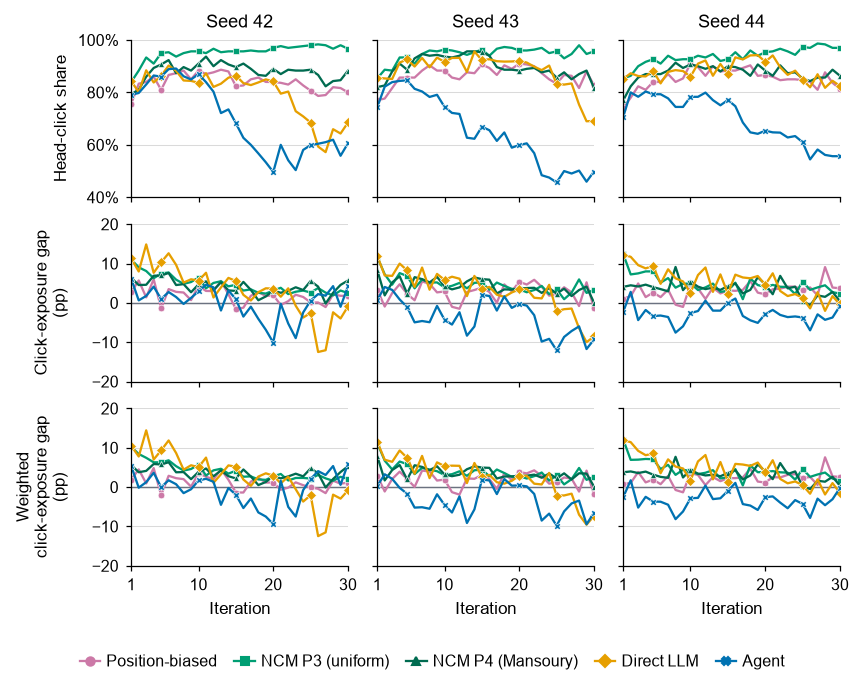

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq2_model_trajectories_l2.pdf) · label `chap:results:fig:main_rq2_model_trajectories_l2`

In [5]:
models_l2 = trajectory.loc[trajectory.study.eq('movielens_feedback_a300_e804') & trajectory.stage.eq('L2_ml_model')]
figure = mt.model_trajectories(models_l2, ['head_click_share', 'click_exposure_gap', 'weighted_click_exposure_gap'],
                               percentage_points=['click_exposure_gap', 'weighted_click_exposure_gap'],
                               limits={'head_click_share': (.4, 1), 'click_exposure_gap': (-20, 20), 'weighted_click_exposure_gap': (-20, 20)})
main_figures.append(mt.export_main_figure(report, figure, 'main_rq2_model_trajectories_l2', ""))

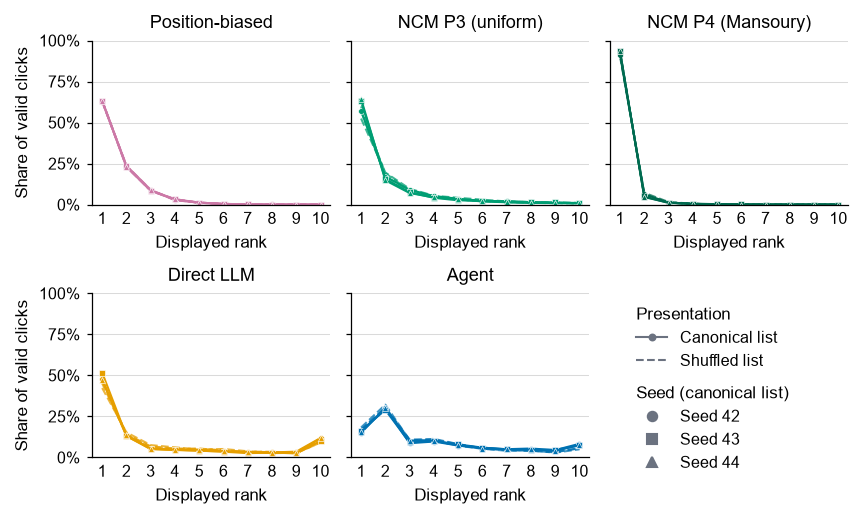

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq2_clicked_ranks_l2.pdf) · label `chap:results:fig:main_rq2_clicked_ranks_l2`

In [6]:
ranks_l2 = results['ranks'].loc[results['ranks'].study.eq('movielens_feedback_a300_e804') & results['ranks'].stage.eq('L2_ml_model')]
rank_counts = rank_summary(ranks_l2)
figure = mt.rank_panels(rank_counts, arms=('canonical', 'shuffled'))
main_figures.append(mt.export_main_figure(report, figure, 'main_rq2_clicked_ranks_l2', ""))

## RQ III: agent ablations


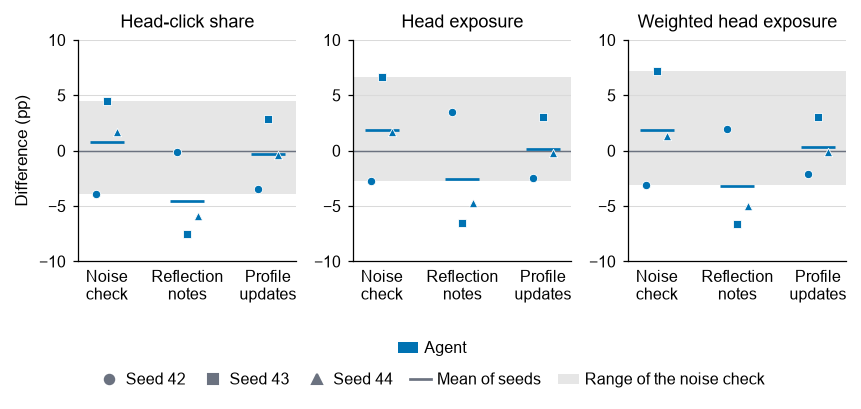

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq3_ablation_effects.pdf) · label `chap:results:fig:main_rq3_ablation_effects`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,Noise check,Agent,Head-click share,-3.92734,4.47714,1.70323,0.751009,3
1,Noise check,Agent,Head exposure,-2.77889,6.63111,1.70444,1.85222,3
2,Noise check,Agent,Weighted head exposure,-3.06531,7.22064,1.33579,1.83037,3
3,Reflection notes,Agent,Head-click share,-0.0732353,-7.53558,-5.88471,-4.49784,3
4,Reflection notes,Agent,Head exposure,3.5,-6.56,-4.70444,-2.58815,3
5,Reflection notes,Agent,Weighted head exposure,1.98599,-6.6214,-5.02052,-3.21864,3
6,Profile updates,Agent,Head-click share,-3.46881,2.835,-0.376843,-0.336885,3
7,Profile updates,Agent,Head exposure,-2.45889,3.04778,-0.217778,0.123704,3
8,Profile updates,Agent,Weighted head exposure,-2.07418,3.07511,-0.105582,0.298448,3


LaTeX label: `chap:results:tab:main_rq3_ablation_effects_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq3_ablation_effects_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq3_ablation_effects_values.csv)

In [7]:
from reported_runs.analysis.agent_ablation_views import ABLATION_COMPARISON_ORDER, label_ablation_comparisons
ablations = label_ablation_comparisons(effect_summaries.loc[effect_summaries.study.eq('movielens_feedback_a300_e804') & effect_summaries.kind.eq('ablation')])
F5_LABELS = dict(zip(ABLATION_COMPARISON_ORDER, ['Noise\ncheck', 'Reflection\nnotes', 'Profile\nupdates']))
figure = mt.effect_panels(ablations, ['head_click_share', 'head_exposure', 'weighted_head_exposure'], categories=list(ABLATION_COMPARISON_ORDER),
                          category_labels=F5_LABELS, layout='columns', reference_category=ABLATION_COMPARISON_ORDER[0])
main_figures.append(mt.export_main_figure(report, figure, 'main_rq3_ablation_effects', ""))
report.table(mt.effect_values(figure.plotted, category_labels=F5_LABELS), 'main_rq3_ablation_effects_values',
             "")

In [8]:
from reported_runs.analysis.agent_usage import load_agent_usage
usage_sources = sources.loc[sources.model.eq('agentic_recommender') & sources.study.eq('movielens_feedback_a300_e804') & sources.stage.str.startswith(('L2', 'L3'))]
usage = load_agent_usage(usage_sources, repo, repo / 'reported_runs/analysis/cache/agent_usage')
agent_diagnostics = label_conditions(results['agent'].loc[results['agent'].study.eq('movielens_feedback_a300_e804')
    & results['agent'].model.eq('agentic_recommender') & results['agent'].stage.str.startswith(('L2', 'L3'))])
module_use = mt.agent_module_table(usage, agent_diagnostics)
report.table(module_use, 'main_rq3_agent_module_use',
             "", source_frame=usage)

,Configuration,Seed,Decisions,Memory-module calls,Forced actions,Reflection requests,Failed reflections,Applied profile changes,Users with a change by iteration 30
0,L2 frozen agent,42,9000,0,0,0,0,0,0
1,L2 frozen agent,43,9000,0,0,0,0,0,0
2,L2 frozen agent,44,9000,0,0,0,0,0,0
3,L3 no reflection,42,9000,0,0,0,0,0,0
4,L3 no reflection,43,9000,0,0,0,0,0,0
5,L3 no reflection,44,9000,0,0,0,0,0,0
6,L3 fixed profile,42,9000,0,0,9000,0,0,0
7,L3 fixed profile,43,9000,0,0,9000,0,0,0
8,L3 fixed profile,44,9000,0,0,9000,0,0,0
9,L3 full reflection,42,9000,0,0,9000,0,1190,267


LaTeX label: `chap:results:tab:main_rq3_agent_module_use` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq3_agent_module_use.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq3_agent_module_use.csv)

## RQ IV: mitigation


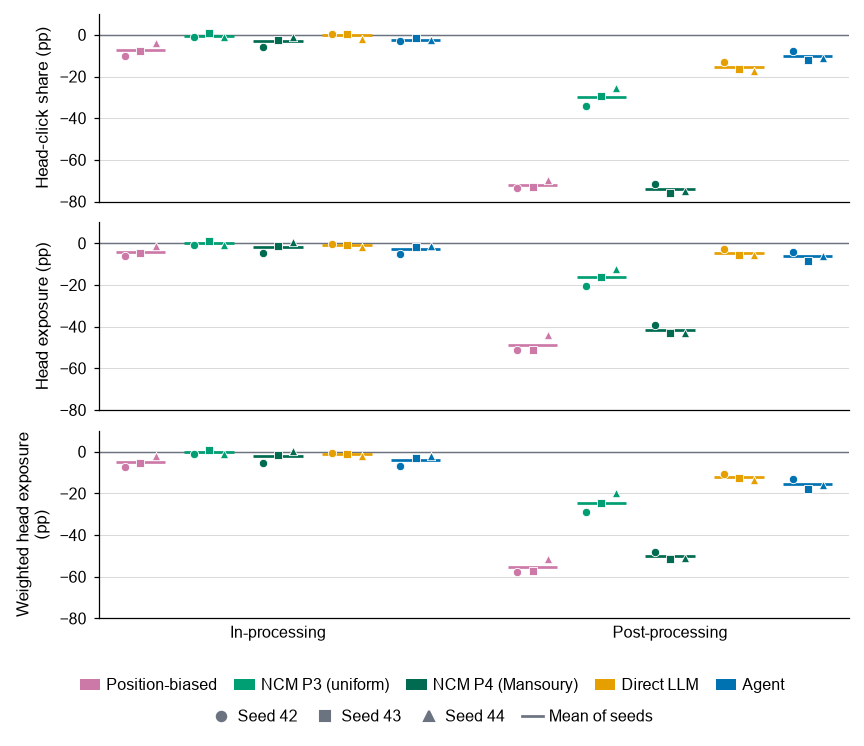

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq4_mitigation_effects.pdf) · label `chap:results:fig:main_rq4_mitigation_effects`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,In-processing,Position-biased,Head-click share,-10.0556,-7.62222,-3.94444,-7.20741,3
1,In-processing,Position-biased,Head exposure,-6.32111,-4.44222,-1.23333,-3.99889,3
2,In-processing,Position-biased,Weighted head exposure,-7.37917,-5.35421,-2.03244,-4.92194,3
3,In-processing,NCM P3 (uniform),Head-click share,-1.17778,0.844444,-1.13333,-0.488889,3
4,In-processing,NCM P3 (uniform),Head exposure,-0.727778,1.25889,-0.672222,-0.047037,3
5,In-processing,NCM P3 (uniform),Weighted head exposure,-0.846779,1.03588,-0.926725,-0.245874,3
6,In-processing,NCM P4 (Mansoury),Head-click share,-5.87778,-2.32222,-1.01111,-3.07037,3
7,In-processing,NCM P4 (Mansoury),Head exposure,-4.89111,-1.15778,0.605556,-1.81444,3
8,In-processing,NCM P4 (Mansoury),Weighted head exposure,-5.32465,-1.33534,0.325065,-2.11164,3
9,In-processing,Direct LLM,Head-click share,0.627439,0.507662,-1.96637,-0.277091,3


LaTeX label: `chap:results:tab:main_rq4_mitigation_effects_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq4_mitigation_effects_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq4_mitigation_effects_values.csv)

In [9]:
rq4_effects = effect_summaries.loc[effect_summaries.study.eq('movielens_mitigation_a300_e804') & effect_summaries.kind.eq('mitigation')].assign(
    method=lambda frame: frame.intervention.map({'in_processing': 'In-processing', 'post_processing': 'Post-processing'}))
figure = mt.effect_panels(rq4_effects, ['head_click_share', 'head_exposure', 'weighted_head_exposure'], category='method',
                          categories=['In-processing', 'Post-processing'], step=10)
main_figures.append(mt.export_main_figure(report, figure, 'main_rq4_mitigation_effects', ""))
report.table(mt.effect_values(figure.plotted, category='method'), 'main_rq4_mitigation_effects_values',
             "")

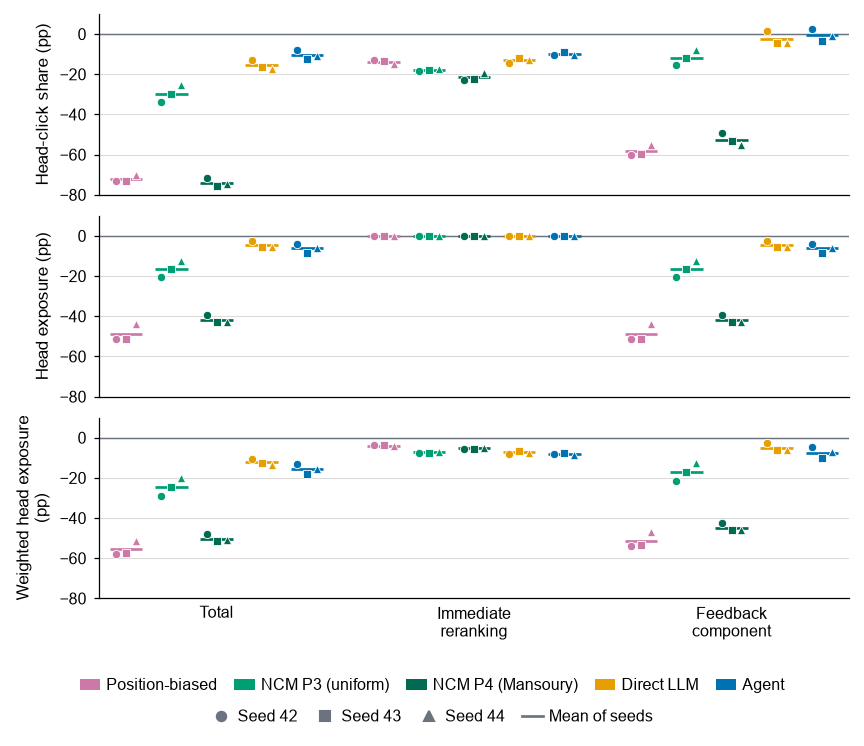

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq4_post_processing_components.pdf) · label `chap:results:fig:main_rq4_post_processing_components`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,Total,Position-biased,Head-click share,-73.3,-72.9111,-69.9,-72.037,3
1,Total,Position-biased,Head exposure,-51.4244,-51.0633,-43.9044,-48.7974,3
2,Total,Position-biased,Weighted head exposure,-57.6779,-57.308,-51.2907,-55.4256,3
3,Total,NCM P3 (uniform),Head-click share,-33.9556,-29.5667,-25.2889,-29.6037,3
4,Total,NCM P3 (uniform),Head exposure,-20.4811,-16.2444,-12.2756,-16.3337,3
5,Total,NCM P3 (uniform),Weighted head exposure,-28.7844,-24.7371,-19.8692,-24.4636,3
6,Total,NCM P4 (Mansoury),Head-click share,-71.7556,-75.7333,-74.8,-74.0963,3
7,Total,NCM P4 (Mansoury),Head exposure,-39.3444,-42.8722,-43.0233,-41.7467,3
8,Total,NCM P4 (Mansoury),Weighted head exposure,-48.008,-51.5534,-51.0624,-50.208,3
9,Total,Direct LLM,Head-click share,-12.8412,-16.1867,-17.4625,-15.4968,3


LaTeX label: `chap:results:tab:main_rq4_post_processing_components_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq4_post_processing_components_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq4_post_processing_components_values.csv)

In [10]:
from reported_runs.analysis.mitigation_decomposition import load_postprocessing_components
from reported_runs.analysis.mitigation_decomposition_views import DECOMPOSITION_METRICS, COMPONENT_ORDER, build_postprocessing_decomposition
rq4_sources = sources.loc[sources.study.eq('movielens_mitigation_a300_e804')]
post_components = load_postprocessing_components(rq4_sources.loc[rq4_sources.intervention.eq('post_processing')], repo,
                                                 repo / 'reported_runs/analysis/cache/mitigation_decomposition')
controls = trajectory.loc[trajectory.study.eq('movielens_mitigation_a300_e804') & trajectory.intervention.eq('control')]
component_effects = build_postprocessing_decomposition(post_components, controls, results['comparison_plan'])['summaries']
F7_LABELS = {'Total': 'Total', 'Immediate reranking': 'Immediate\nreranking', 'Feedback component': 'Feedback\ncomponent'}
figure = mt.effect_panels(component_effects, list(DECOMPOSITION_METRICS), category='component_label', categories=list(COMPONENT_ORDER),
                          category_labels=F7_LABELS, step=10)
main_figures.append(mt.export_main_figure(report, figure, 'main_rq4_post_processing_components', ""))
report.table(mt.effect_values(figure.plotted, category='component_label'), 'main_rq4_post_processing_components_values',
             "")

## RQ V: order sensitivity


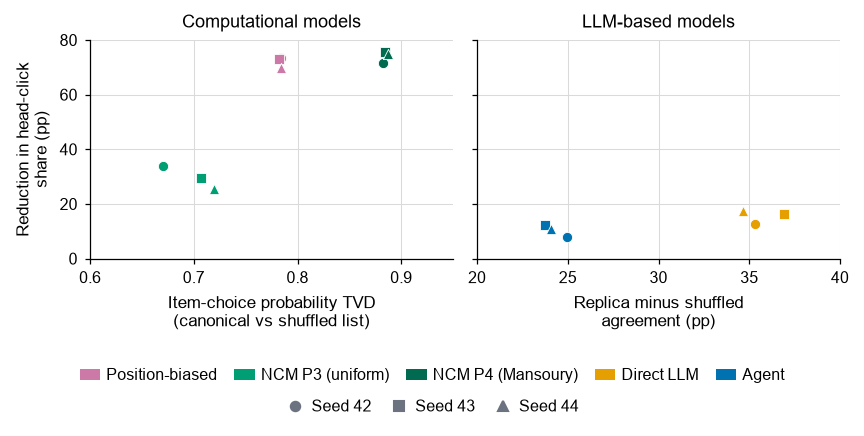

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq5_order_sensitivity.pdf) · label `chap:results:fig:main_rq5_order_sensitivity`

,predictor_family,Model,seed,baseline_order_sensitivity,head_click_reduction_pp
0,LLM common-valid agreement gap,Agent,42,0.249772,7.93692
1,LLM common-valid agreement gap,Direct LLM,42,0.353267,12.8412
2,Computational probability TVD,NCM P4 (Mansoury),42,0.882039,71.7556
3,Computational probability TVD,NCM P3 (uniform),42,0.670173,33.9556
4,Computational probability TVD,Position-biased,42,0.784146,73.3
5,LLM common-valid agreement gap,Agent,43,0.23724,12.2005
6,LLM common-valid agreement gap,Direct LLM,43,0.36913,16.1867
7,Computational probability TVD,NCM P4 (Mansoury),43,0.884852,75.7333
8,Computational probability TVD,NCM P3 (uniform),43,0.707137,29.5667
9,Computational probability TVD,Position-biased,43,0.781691,72.9111


LaTeX label: `chap:results:tab:main_rq5_order_sensitivity_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq5_order_sensitivity_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq5_order_sensitivity_values.csv)

In [11]:
order_pairs = results['order_pairs']
figure = mt.order_sensitivity_panels(order_pairs)
main_figures.append(mt.export_main_figure(report, figure, 'main_rq5_order_sensitivity', ""))
order_values = figure.plotted.assign(Model=lambda frame: frame.model.map(mt.MODEL_LABELS))[
    ['predictor_family', 'Model', 'seed', 'baseline_order_sensitivity', 'head_click_reduction_pp']]
report.table(order_values, 'main_rq5_order_sensitivity_values',
             "")

## RQ VI: popularity bias in Goodreads


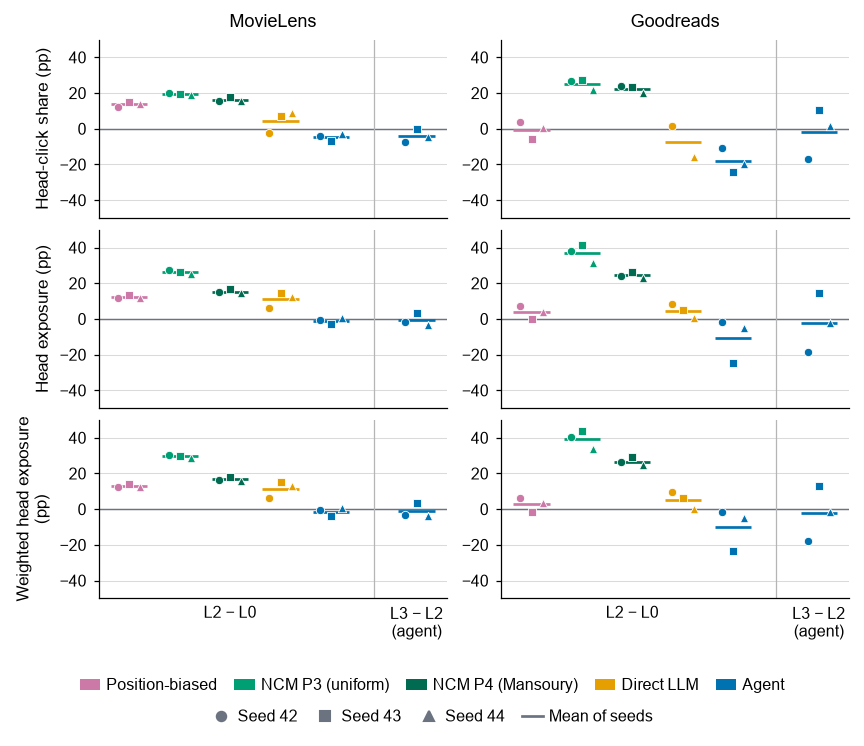

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq6_cross_dataset_popularity.pdf) · label `chap:results:fig:main_rq6_cross_dataset_popularity`

,Dataset,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,movielens,L2 minus L0,Position-biased,Head-click share,12.4333,14.9556,13.7667,13.7185,3
1,movielens,L2 minus L0,Position-biased,Head exposure,11.7156,13.3922,11.4867,12.1981,3
2,movielens,L2 minus L0,Position-biased,Weighted head exposure,12.1541,13.8925,12.1553,12.7339,3
3,movielens,L2 minus L0,NCM P3 (uniform),Head-click share,20.1889,19.6556,18.6778,19.5074,3
4,movielens,L2 minus L0,NCM P3 (uniform),Head exposure,27.1611,26.3644,25.2956,26.2737,3
5,movielens,L2 minus L0,NCM P3 (uniform),Weighted head exposure,30.3137,29.7381,28.7493,29.6004,3
6,movielens,L2 minus L0,NCM P4 (Mansoury),Head-click share,15.8333,17.7,15.4556,16.3296,3
7,movielens,L2 minus L0,NCM P4 (Mansoury),Head exposure,14.8511,16.6289,14.3478,15.2759,3
8,movielens,L2 minus L0,NCM P4 (Mansoury),Weighted head exposure,16.5352,18.239,15.8341,16.8694,3
9,movielens,L2 minus L0,Direct LLM,Head-click share,-2.2205,7.00075,8.85729,4.54585,3


LaTeX label: `chap:results:tab:main_rq6_cross_dataset_popularity_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq6_cross_dataset_popularity_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq6_cross_dataset_popularity_values.csv)

In [12]:
from reported_runs.analysis.sections_rq6_7 import POPULARITY, GENDER_ALL, transfer_effects, gender_mitigation_effects
transfer = transfer_effects(effect_summaries)
F9_LABELS = {'L2 minus L0': 'L2 − L0', 'L3 full reflection minus L2 frozen agent': 'L3 − L2\n(agent)'}
figure = mt.effect_panels(transfer, POPULARITY, categories=list(F9_LABELS), category_labels=F9_LABELS, facet='dataset',
                          facet_labels={'movielens': 'MovieLens', 'goodreads': 'Goodreads'},
                          separators=['L3 full reflection minus L2 frozen agent'], limits=(-50, 50))
main_figures.append(mt.export_main_figure(report, figure, 'main_rq6_cross_dataset_popularity', ""))
report.table(mt.effect_values(figure.plotted, category_labels=F9_LABELS, facet='dataset'), 'main_rq6_cross_dataset_popularity_values',
             "")

## RQ VII: author-gender representation in Goodreads


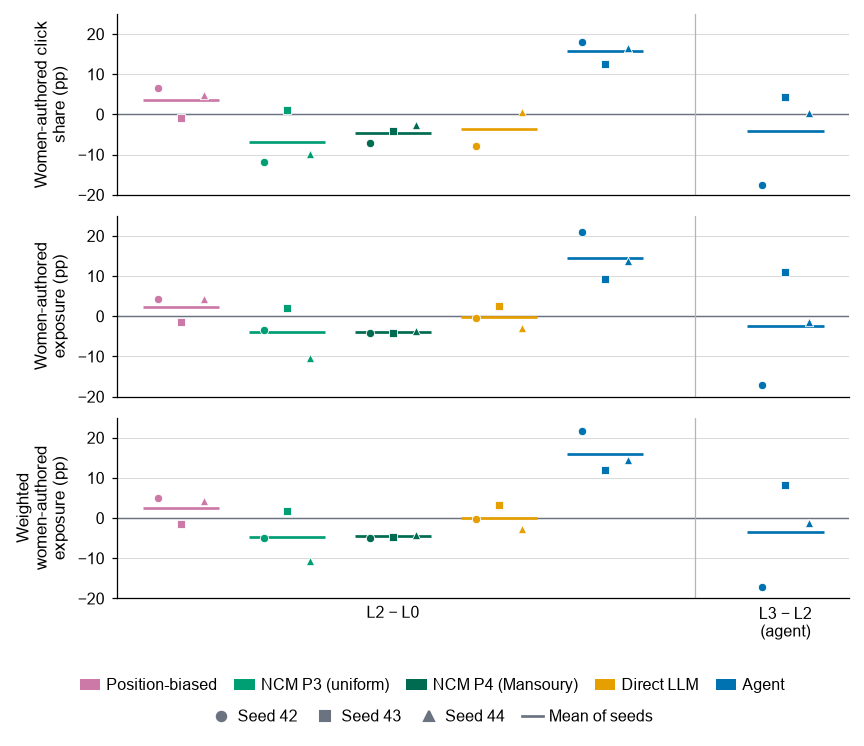

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq7_gender_feedback_effects.pdf) · label `chap:results:fig:main_rq7_gender_feedback_effects`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,L2 minus L0,Position-biased,Women-authored click share,6.47778,-0.8,4.88889,3.52222,3
1,L2 minus L0,Position-biased,Women-authored exposure,4.30667,-1.37778,4.19111,2.37333,3
2,L2 minus L0,Position-biased,Weighted women-authored exposure,5.0222,-1.35935,4.13883,2.60056,3
3,L2 minus L0,NCM P3 (uniform),Women-authored click share,-11.8556,1.13333,-9.84444,-6.85556,3
4,L2 minus L0,NCM P3 (uniform),Women-authored exposure,-3.35444,1.95222,-10.3444,-3.91556,3
5,L2 minus L0,NCM P3 (uniform),Weighted women-authored exposure,-5.06792,1.6536,-10.6561,-4.69014,3
6,L2 minus L0,NCM P4 (Mansoury),Women-authored click share,-7.18889,-4.17778,-2.55556,-4.64074,3
7,L2 minus L0,NCM P4 (Mansoury),Women-authored exposure,-4.16111,-4.15,-3.78778,-4.03296,3
8,L2 minus L0,NCM P4 (Mansoury),Weighted women-authored exposure,-4.89125,-4.68133,-4.1006,-4.55773,3
9,L2 minus L0,Direct LLM,Women-authored click share,-7.95984,—,0.70393,-3.62796,2


LaTeX label: `chap:results:tab:main_rq7_gender_feedback_effects_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq7_gender_feedback_effects_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq7_gender_feedback_effects_values.csv)

In [13]:
gender_effects = transfer.loc[transfer.dataset.eq('goodreads')]
figure = mt.effect_panels(gender_effects, GENDER_ALL, categories=list(F9_LABELS), category_labels=F9_LABELS,
                          separators=['L3 full reflection minus L2 frozen agent'])
main_figures.append(mt.export_main_figure(report, figure, 'main_rq7_gender_feedback_effects', ""))
report.table(mt.effect_values(figure.plotted, category_labels=F9_LABELS), 'main_rq7_gender_feedback_effects_values',
             "")

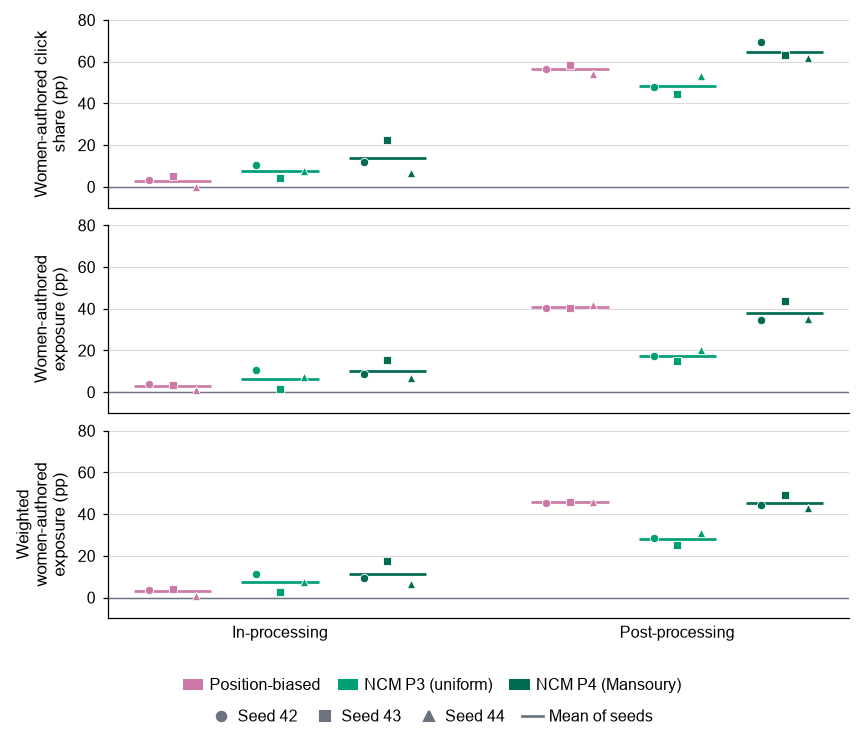

[PDF](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq7_gender_mitigation_l2.pdf) · label `chap:results:fig:main_rq7_gender_mitigation_l2`

,Contrast,Model,Metric,Seed 42,Seed 43,Seed 44,Mean of seeds,Seeds
0,In-processing,Position-biased,Women-authored click share,3.32222,5.43333,-0.288889,2.82222,3
1,In-processing,Position-biased,Women-authored exposure,4.05556,3.68778,1.03778,2.92704,3
2,In-processing,Position-biased,Weighted women-authored exposure,3.77131,4.25375,0.916259,2.98044,3
3,In-processing,NCM P3 (uniform),Women-authored click share,10.6111,4.4,7.71111,7.57407,3
4,In-processing,NCM P3 (uniform),Women-authored exposure,10.5967,1.45667,7.06556,6.37296,3
5,In-processing,NCM P3 (uniform),Weighted women-authored exposure,11.5226,2.84526,7.50694,7.2916,3
6,In-processing,NCM P4 (Mansoury),Women-authored click share,11.7444,22.6444,6.56667,13.6519,3
7,In-processing,NCM P4 (Mansoury),Women-authored exposure,8.63556,15.6556,6.64667,10.3126,3
8,In-processing,NCM P4 (Mansoury),Weighted women-authored exposure,9.55903,17.3559,6.68071,11.1986,3
9,Post-processing,Position-biased,Women-authored click share,56.4111,58.3222,54.2667,56.3333,3


LaTeX label: `chap:results:tab:main_rq7_gender_mitigation_l2_values` · [table](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq7_gender_mitigation_l2_values.tex) · [numeric CSV](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/tables/main_rq7_gender_mitigation_l2_values.csv)

In [14]:
gender_mitigation = gender_mitigation_effects(effect_summaries)
gender_mitigation_l2 = gender_mitigation.loc[gender_mitigation.stage.eq('L2_ml_model')]
F11_LABELS = {'L2 in-processing minus control': 'In-processing', 'L2 post-processing minus control': 'Post-processing'}
figure = mt.effect_panels(gender_mitigation_l2, GENDER_ALL, categories=list(F11_LABELS), category_labels=F11_LABELS, step=10)
main_figures.append(mt.export_main_figure(report, figure, 'main_rq7_gender_mitigation_l2', ""))
report.table(mt.effect_values(figure.plotted, category_labels=F11_LABELS), 'main_rq7_gender_mitigation_l2_values',
             "")

## Refresh the Goodreads figures in the thesis


In [15]:
refreshed = ['main_rq6_cross_dataset_popularity', 'main_rq7_gender_feedback_effects']
figure_dir = report.exports / 'figures'
display(Markdown('\n'.join(f'- [{name}.pdf]({(figure_dir / (name + ".pdf")).as_posix()})' for name in refreshed)))

[main_rq6_cross_dataset_popularity.pdf](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq6_cross_dataset_popularity.pdf) · [main_rq7_gender_feedback_effects.pdf](../../../reported_runs/analysis/snapshots/results_20261116_goodreads_agent_l0/exports/figures/main_rq7_gender_feedback_effects.pdf)